# Identifying Significant Predictors of Industrial Equipment Failure

**AAI-500 Final Team Project, Team 1:** Justin Nguyen, Kyle Abaya
**Dataset:** AI4I 2020 Predictive Maintenance Dataset (UCI Machine Learning
Repository, id 601), 10,000 records

**Contents**
1. Data Loading
2. Data Cleaning and Preparation
3. Exploratory Data Analysis
   - 3.1 Sensor distributions: operational vs. failed
   - 3.2 Failure rate by product quality type
   - 3.3 Statistical tests: operational vs. failed
   - 3.4 Sensor profiles by failure mode
   - 3.5 Correlation between sensors
   - 3.6 Physics-Based Features
   - 3.7 EDA summary
4. Modeling
   - 4.1 Train/test split and discretization
   - 4.2 Bayesian networks
   - 4.3 Logistic regression
   - 4.4 Model comparison
   - 4.5 Modeling summary

## 1. DATA LOADING

In [441]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from ucimlrepo import fetch_ucirepo
pd.set_option('display.max_columns', None)
pd.set_option('display.max_rows', None)
pd.set_option('display.width', None)

# Fetch the predictive maintenance dataset from the UCI repository
predictive_maintenance_dataset = fetch_ucirepo(id=601)
X = predictive_maintenance_dataset.data.features
Y = predictive_maintenance_dataset.data.targets
df = pd.concat([X, Y], axis=1)
print(df.head())
print(df.shape)
df.info()

# Display class distribution for the target variable
print(df['Machine failure'].value_counts(normalize=True))

# Check for missing values in the dataset
print(df.isna().sum().sum())

  Type  Air temperature  Process temperature  Rotational speed  Torque  \
0    M            298.1                308.6              1551    42.8   
1    L            298.2                308.7              1408    46.3   
2    L            298.1                308.5              1498    49.4   
3    L            298.2                308.6              1433    39.5   
4    L            298.2                308.7              1408    40.0   

   Tool wear  Machine failure  TWF  HDF  PWF  OSF  RNF  
0          0                0    0    0    0    0    0  
1          3                0    0    0    0    0    0  
2          5                0    0    0    0    0    0  
3          7                0    0    0    0    0    0  
4          9                0    0    0    0    0    0  
(10000, 12)
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 12 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -

**INTERPRETATION:**

The dataset has 12 columns: one categorical (Type), five numeric sensor readings, the binary target (Machine Failure), and the five failure-modes. This dataset has no missing values, therefore, imputation is unnecessary.

The target is imbalanced with only 3.39% of the sample records are failures. A model that always predicts "no failure" would be 96.6% accurate while catching zero failures.

## 2. DATA CLEANING AND PREPARATION

In [442]:
# Identify failure conditions and sensor readings columns in the dataset
failure_conditions = df.columns[-5:]
sensor_readings = df.columns[:-6]

print("Failure conditions columns:", failure_conditions)
print("Sensor readings columns:", sensor_readings)

Failure conditions columns: Index(['TWF', 'HDF', 'PWF', 'OSF', 'RNF'], dtype='object')
Sensor readings columns: Index(['Type', 'Air temperature', 'Process temperature', 'Rotational speed',
       'Torque', 'Tool wear'],
      dtype='object')


**INTERPRETATION:**

There are 5 failure condition flags: TWF, HDF, PWF, OSF, and RNF. These record why a machine failed. These will not be used as predictors in the model as this would lead to data leakage, but they will be used to help understand the state of the failure.

In [443]:
num_modes = df[failure_conditions].sum(axis=1)
print(pd.crosstab(num_modes > 0, df['Machine failure'],
                  rownames=['Any failure mode'],
                  colnames=['Machine failure']))


failure_no_mode = df[(df['Machine failure'] == 1) & (num_modes == 0)]
mode_no_failure = df[(df['Machine failure'] == 0) & (num_modes > 0)]

print('Failures with no recorded failure mode:', len(failure_no_mode))
print('Failure modes with no recorded failure:', len(mode_no_failure))
print(mode_no_failure[failure_conditions].sum())
print('Rows with more than one failure mode:', (num_modes > 1).sum())

Machine failure      0    1
Any failure mode           
False             9643    9
True                18  330
Failures with no recorded failure mode: 9
Failure modes with no recorded failure: 18
TWF     0
HDF     0
PWF     0
OSF     0
RNF    18
dtype: int64
Rows with more than one failure mode: 24


**INTERPRETATION:**

In this dataset, there exist significant inconsistencies:

- 9 rows are marked as failures but have no recorded cause.
- 18 rows have a failure-mode flag but are not flagged as a machine failure. These are all random failures.
- 24 failures were caused by multiple modes at the same time, but are valid and will be kept.

Conclusion: For cleaning, we will remove the 9 rows that are marked as failures but have no recorded cause since there are no failure mechanisms that can back up the failure, but we will keep the 18 RNF as non-failures as random failures are unpredictable.

In [444]:
df = df.drop(index = failure_no_mode.index).reset_index(drop=True)
print('Rows after cleaning:', len(df))
print('Failures after cleaning:', df['Machine failure'].sum())
print('Failure rate after cleaning:', round(df['Machine failure'].mean(),3))

Rows after cleaning: 9991
Failures after cleaning: 330
Failure rate after cleaning: 0.033


After cleaning, we are left with 9991 rows, 330 failures, and a 3.3% failure rate.

In [445]:
# split the dataset into operational and failed machines
operational = df[df['Machine failure'] == 0]
failed = df[df['Machine failure'] == 1]

print('Operational machines:', len(operational))
print('Failed machines:', len(failed))

Operational machines: 9661
Failed machines: 330


## 3. EXPLORATORY DATA ANALYSIS

### 3.1 Sensor Distributions: Operational vs. Failed

Comparing sensor distributions for operational machines and failed machines

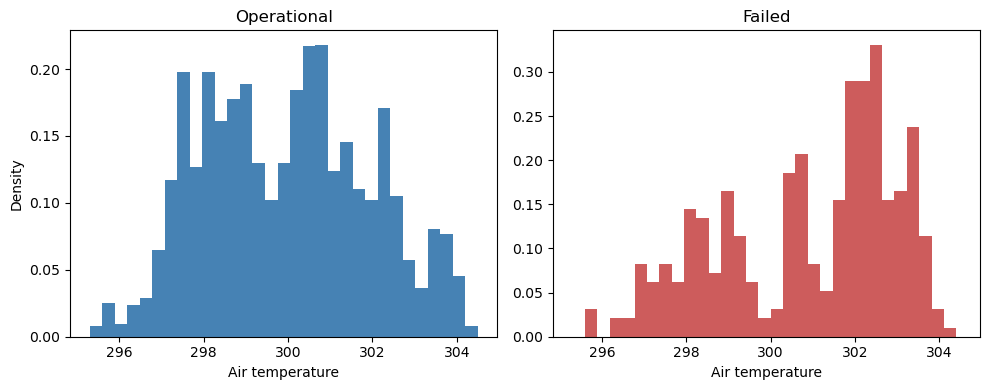

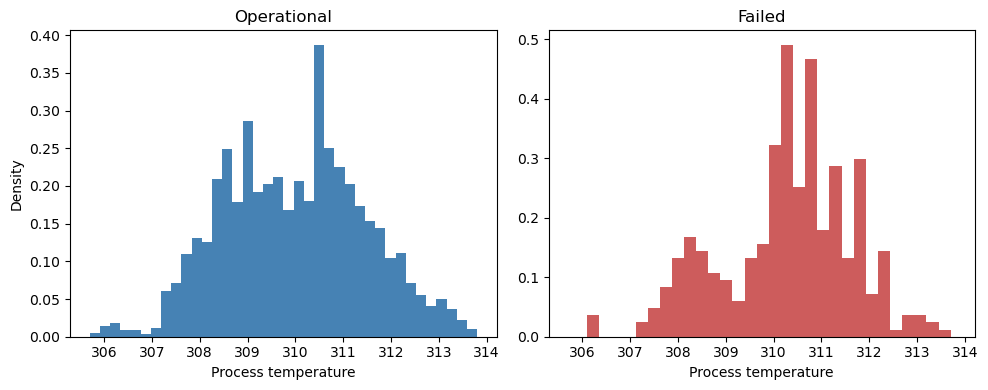

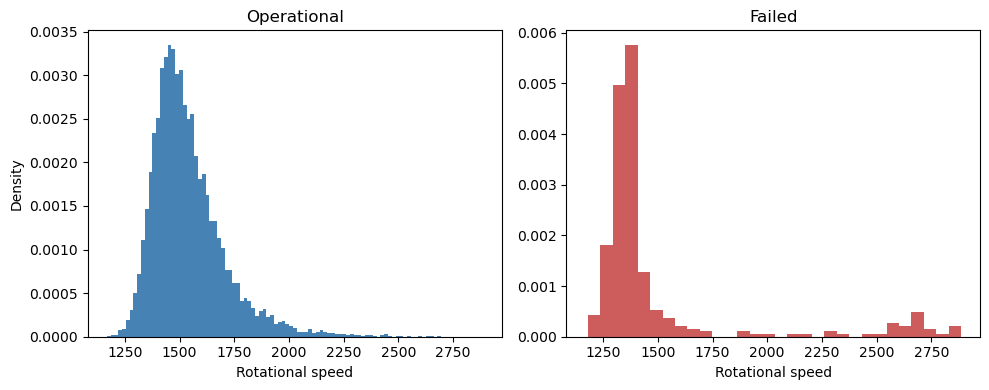

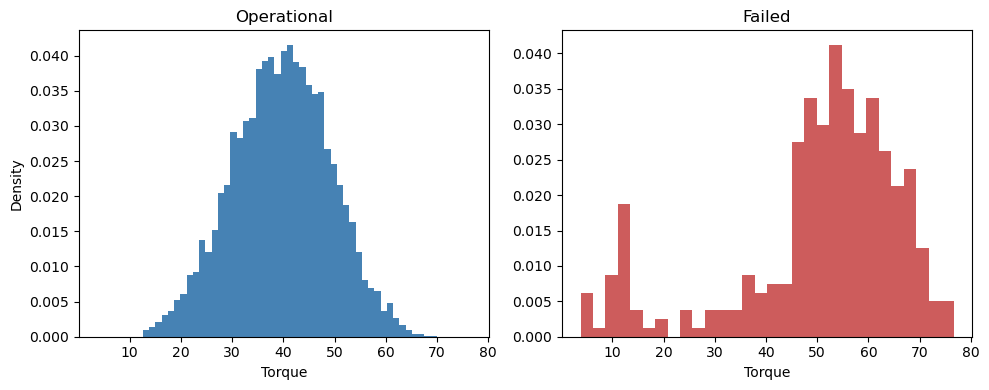

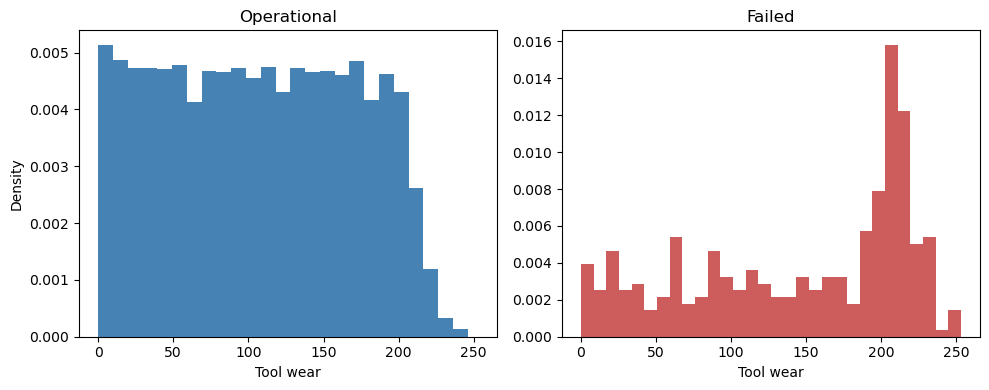

In [446]:
for sensor_reading in sensor_readings[1:]:
    fig, axes = plt.subplots(1, 2, figsize=(10, 4), sharex=True, sharey=False)

    axes[0].hist(operational[sensor_reading], bins='auto', density=True, color='steelblue')
    axes[0].set_title('Operational')
    axes[0].set_xlabel(sensor_reading)
    axes[0].set_ylabel('Density')

    axes[1].hist(failed[sensor_reading], bins=30, density=True, color='indianred')
    axes[1].set_title('Failed')
    axes[1].set_xlabel(sensor_reading)

    plt.tight_layout()
    plt.show()

**INTERPRETATION:**

Observations based on the histograms:

1.) **Air Temperature**: Failed machines lean towards the higher end of the range, operational machines are more balanced.

2.) **Process Temperature:** Both distributions showcase a similar trend, little to no 
difference with failed machines leaning towards the higher end.

3.) **Rotational speed:** Both distributions are right-skewed with their peaks at the lower end of the range, so the overall shape is similar. The failed distribution is narrower and sits slightly lower, with 64% of failures between 1,300 and 1,450 rpm versus 30% of operational machines. Failures also show a small second cluster at very high speeds (above 2,400 rpm), which operational machines largely lack.

4.) **Torque**: Failed machines lean towards higher torque, and the distribution is wide, with some failures at lower torque.

5.) **Tool Wear**: Failures pile up at high tool wear at the 200+ minute mark.



### 3.2 Failure rate by product quality type

Products come in three quality types: L (LOW), M (MEDIUM), H (HIGH)

      size  sum      mean  failure_rate
Type                                   
L     5996  231  0.038526      3.852568
M     2993   79  0.026395      2.639492
H     1002   20  0.019960      1.996008

Chi-square = 15.15, df = 2, p = 0.0005


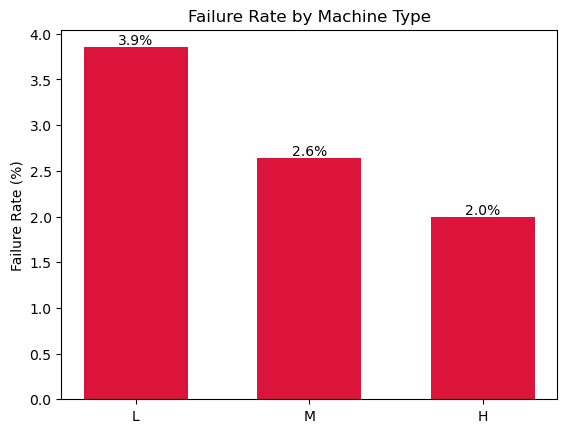

In [447]:
import scipy.stats as stats
type_summary = (df.groupby('Type')['Machine failure'].agg(['size', 'sum', 'mean']).reindex(['L', 'M', 'H']))
type_summary['failure_rate'] = (type_summary['mean']*100)
print(type_summary)

# Chi-square test for independence between 'Type' and 'Machine failure'
contingency = pd.crosstab(df['Type'], df['Machine failure'])
chi2, p_value, dof, _ = stats.chi2_contingency(contingency)
print(f'\nChi-square = {chi2:.2f}, df = {dof}, p = {p_value:.4f}')

fig, ax = plt.subplots()
bars = ax.bar(type_summary.index, type_summary['failure_rate'],
              color='crimson', width=0.6)
ax.bar_label(bars, fmt='%.1f%%')
ax.set_ylabel('Failure Rate (%)')
ax.set_title('Failure Rate by Machine Type')

plt.show()

**INTERPRETATION:**

Failure rates decrease as quality type increase. L fails at 3.9%, M fails at 2.6%, and H at 2.0%. A chi-square test of independence shows the difference is statistically significant with Chi-square = 15.15, df = 2, p = 0.0005, quality type is related to failure and will be included in the model.

It is noted that 60% of products are L, 30% are M, 10% are H, and 231 out of 330 failures are from L products.

### 3.3 Statistical Tests: Operational vs Failed

Statistical testing whether each sensor's average is significantly different between failed and operational machines by using Welch's t-test because both groups have very different sizes and variances.

In [448]:
rows = []
for sensor in sensor_readings[1: ]:
    t_stat, p_val = stats.ttest_ind(failed[sensor], operational[sensor], equal_var=False)
    rows.append({'Sensor': sensor, 'Operational mean': operational[sensor].mean(), 'Failed mean': failed[sensor].mean(), 'Difference': failed[sensor].mean() - operational[sensor].mean(), 't_stat': t_stat, 'p_val': p_val})

ttest_results = pd.DataFrame(rows).set_index('Sensor')
with pd.option_context('display.float_format', '{:.4g}'.format):
    print(ttest_results)

                     Operational mean  Failed mean  Difference  t_stat  \
Sensor                                                                   
Air temperature                   300        300.9      0.9275   8.002   
Process temperature               310        310.3      0.2972   3.866   
Rotational speed                 1540         1496      -44.08  -2.049   
Torque                          39.63         50.4       10.77   11.82   
Tool wear                       106.7        144.5       37.81     9.3   

                        p_val  
Sensor                         
Air temperature     1.817e-14  
Process temperature 0.0001315  
Rotational speed      0.04126  
Torque              3.339e-27  
Tool wear           1.637e-18  


**INTERPRETATION:**

Based on the Welch's t-test results, all five sensors differ significantly between failed and operational machines at the 0.05 level in decreasing order:

1.) Torque shows the strongest difference with 50.4 for the failed mean and 39.6 for the operational mean at a p-value of 3.34e-27.

2.) Tool wear from about 144.5 for the failed mean and 106.7 for the operational mean at a p-value of 1.64e-18.

3.) Air Temperature is about 0.9 higher in the failed mean at a p-value of 1.82e-14.

4.) Process temperature is about 0.3 higher in the failed mean at a p-value of 0.00013.

5.) Rotational Speed is the weakest at p = 0.04, based on section 3.1, failures happen at both low and high speeds which may have canceled out in the average.

### 3.4 Sensor profiles by failure mode

Each failure mode has its own physical cause, so each should leave a
different "signature" in the sensor readings. To see these signatures clearly, we keep only failures with exactly one failure mode and compute the mean and standard deviation of each sensor for each mode.

This gives us the descriptive statistics of each pure subset of sensor readings grouped by failure conditions

In [449]:
df['num_failure_conditions'] = df[failure_conditions].sum(axis=1)

failed_condition_data = df[df['num_failure_conditions'] == 1].drop(columns=['Machine failure'])
failed_condition_data_mean_std = failed_condition_data.groupby(list(failure_conditions))[sensor_readings[1:]].agg(['mean', 'std'])
print(failed_condition_data_mean_std)

                    Air temperature           Process temperature            \
                               mean       std                mean       std   
TWF HDF PWF OSF RNF                                                           
0   0   0   0   1        300.766667  1.743222          310.755556  1.501459   
            1   0        299.867949  1.954050          310.051282  1.552940   
        1   0   0        300.022500  2.173487          309.961250  1.660981   
    1   0   0   0        302.560377  0.601218          310.801887  0.631398   
1   0   0   0   0        300.269048  1.941522          310.128571  1.498664   

                    Rotational speed                 Torque             \
                                mean         std       mean        std   
TWF HDF PWF OSF RNF                                                      
0   0   0   0   1        1489.444444  110.833326  43.522222  10.861294   
            1   0        1354.243590   59.628544  56.878205   4.904216 

Means and standard deviations for the sensor_readings in the operational group.

In [450]:
operational_sensor_readings_mean_std = operational[sensor_readings[1:]].agg(['mean', 'std'])
print(operational_sensor_readings_mean_std)

      Air temperature  Process temperature  Rotational speed     Torque  \
mean       299.973999           309.995570       1540.260014  39.629655   
std          1.990748             1.486846        167.394734   9.472080   

       Tool wear  
mean  106.693717  
std    62.945790  


We need to find how far the means of the sensor readings of the failed group deviates from the means of the sensor readings of the operational group

In [451]:
failed_means = failed_condition_data_mean_std.xs('mean', axis=1, level=1)
failed_stds = failed_condition_data_mean_std.xs('std', axis=1, level=1)

labels = failed_means.index.to_frame().idxmax(axis=1)
failed_means.index = labels
failed_stds.index = labels

operational_mean = operational_sensor_readings_mean_std.loc['mean']
operational_std = operational_sensor_readings_mean_std.loc['std']

difference_in_mean = failed_means - operational_mean
deviation_from_mean = difference_in_mean / operational_std

print(difference_in_mean.round(2))
print(deviation_from_mean.round(2))

     Air temperature  Process temperature  Rotational speed  Torque  Tool wear
RNF             0.79                 0.76            -50.82    3.89      13.20
OSF            -0.11                 0.06           -186.02   17.25     101.52
PWF             0.05                -0.03            302.98    5.37     -19.07
HDF             2.59                 0.81           -199.55   12.73      -5.47
TWF             0.30                 0.13             42.98   -3.64     109.52
     Air temperature  Process temperature  Rotational speed  Torque  Tool wear
RNF             0.40                 0.51             -0.30    0.41       0.21
OSF            -0.05                 0.04             -1.11    1.82       1.61
PWF             0.02                -0.02              1.81    0.57      -0.30
HDF             1.30                 0.54             -1.19    1.34      -0.09
TWF             0.15                 0.09              0.26   -0.38       1.74


**INTERPRETATION:**

Each failure mode has a distinct signature (z-scores in standard deviations from normal operation):

1.) **HDF - Heat Dissipation Failure**: high air temperature (+1.3), low speed (−1.2), and high torque (+1.3). Heat builds up when the machine runs hot and slow.

2.) **OSF - Overstrain Failure**: high torque (+1.8) combined with high tool wear (+1.6). A worn tool under heavy load gets overstrained.

3.) **TWF - Tool Wear Failure**: high tool wear (+1.7) and nothing else. The tool simply wears out.

4.) **PWF - Power Failure**: the +1.8 speed average is misleading. Its standard deviation is about 646 rpm, nearly four times the operational spread, because these failures happen at both extremes: too little power and too much.

5.) **RNF - Random Failure**: no sensor stands out (all within ±0.5), as
  expected for failures that occur at random. Note that all 18 rows in this group are the RNF flags that were not counted as machine
  failures (Section 2), so this row describes random-failure flags
  rather than actual failures.

The signature analysis shows that single-sensor comparisons are not enough, because different failure modes can push one sensor in opposite directions.


### 3.5 Correlation between sensors

We must check strongly correlated predictors before modeling as they can make logistic regression coefficients and p-values unreliable

                     Air temperature  Process temperature  Rotational speed  \
Air temperature                 1.00                 0.88              0.02   
Process temperature             0.88                 1.00              0.02   
Rotational speed                0.02                 0.02              1.00   
Torque                         -0.01                -0.01             -0.87   
Tool wear                       0.01                 0.01             -0.00   

                     Torque  Tool wear  
Air temperature       -0.01       0.01  
Process temperature   -0.01       0.01  
Rotational speed      -0.87      -0.00  
Torque                 1.00      -0.00  
Tool wear             -0.00       1.00  


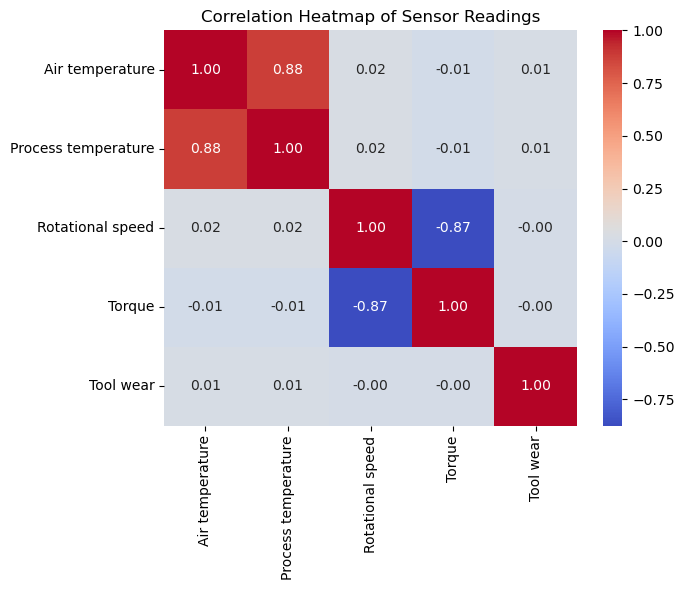

In [452]:
corr = df[sensor_readings[1:]].corr()
print(corr.round(2))

fig, ax = plt.subplots(figsize=(7, 6))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="coolwarm", ax=ax)
ax.set_title("Correlation Heatmap of Sensor Readings")
plt.tight_layout()
plt.show()

**INTERPRETATION:**

1.) **Air temperature and Process Temperature are heavily correlated (r = 0.88)**: the dataset generates process temperature as air temperature plus about 10 K.

2.) **Rotational Speed and Torque (r = -0.87)**: machine runs roughly constant power, so higher rotational speed means lower torque.

3.) **Tool wear** is unrelated to all other sensors.

For Modeling: putting both members of a correlated pair into logistic regression can inflate the standard errors and make individual coefficients harder to interpret.

### 3.6 Physics-Based Features

Based on the dataset documentation which provided the exact rules/equations that trigger each failure mode, we will be converting these rules into features that can better predict failure rather than just the raw sensors.

                 Operational mean  Failed mean      t   p-value
Feature                                                        
Temp difference             10.02        9.391 -9.697 8.004e-20
Power                        6245         7305  10.29 8.895e-22
Strain                       4214         7257  12.92 2.529e-31

Rows with power outside 3,500-9,000 W: 95
Failure rate in those rows: 100.0 %


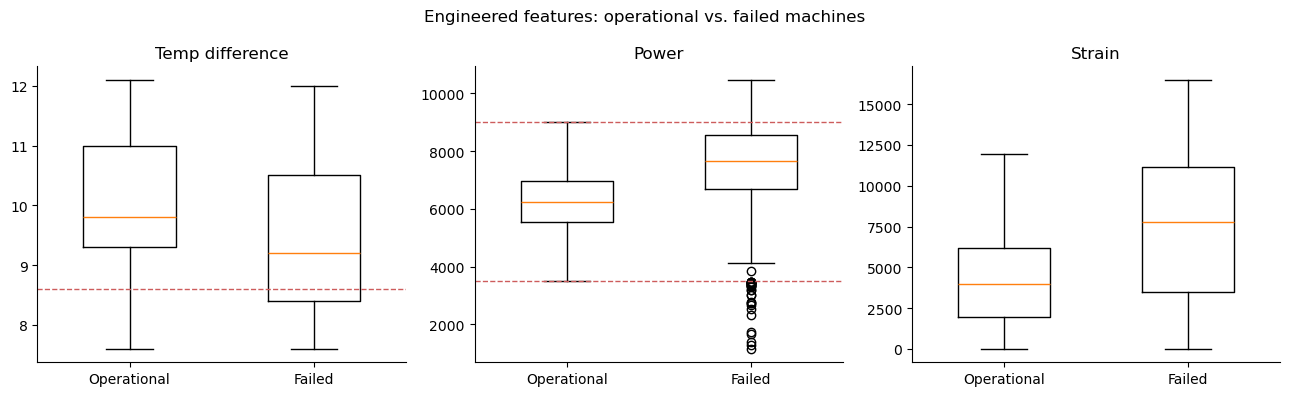

In [453]:
df['Temp difference'] = df['Process temperature'] - df['Air temperature']
df['Power'] = df['Torque'] * df['Rotational speed'] * 2 * np.pi / 60
df['Strain'] = df['Tool wear'] * df['Torque']
engineered_features = ['Temp difference', 'Power', 'Strain']

operational = df[df['Machine failure'] == 0]
failed = df[df['Machine failure'] == 1]

rows = []
for feature in engineered_features:
    t_stat, p_val = stats.ttest_ind(failed[feature], operational[feature],
                                    equal_var=False)
    rows.append({'Feature': feature,
                 'Operational mean': operational[feature].mean(),
                 'Failed mean': failed[feature].mean(),
                 't': t_stat,
                 'p-value': p_val})
with pd.option_context('display.float_format', '{:.4g}'.format):
    print(pd.DataFrame(rows).set_index('Feature'))

power_out_of_range = (df['Power'] < 3500) | (df['Power'] > 9000)
print('\nRows with power outside 3,500-9,000 W:', power_out_of_range.sum())
print('Failure rate in those rows:',
      round(df.loc[power_out_of_range, 'Machine failure'].mean() * 100, 1),
      '%')

fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, feature in zip(axes, engineered_features):
    ax.boxplot([operational[feature], failed[feature]],
               tick_labels=['Operational', 'Failed'], widths=0.5)
    ax.set_title(feature)
    ax.spines[['top', 'right']].set_visible(False)
axes[0].axhline(8.6, color='indianred', linestyle='--', linewidth=1)
axes[1].axhline(3500, color='indianred', linestyle='--', linewidth=1)
axes[1].axhline(9000, color='indianred', linestyle='--', linewidth=1)
fig.suptitle('Engineered features: operational vs. failed machines')
plt.tight_layout()
plt.show()

**INTERPRETATION:**

All of three physics-based features (Strain, Temperature Difference, Power) contrast failed from operational machines with all having p-values less than 0.001:

1.) Strain: shows the largest difference with failed machines averaging 7257 versus 4214 for operational machines

2.) Power: the dashed lines mark the 3500 and 9000 limits and failures go beyond both limits. All 95 machines that ran outside the range failed at 100%.

3.) Temp Difference: Heat dissipation failures occur when the gap between process and air temp become too small to carry heat away

Temperature difference and power each combine one of the correlated pairs from section 3.5 into a single variable; strain combines tool wear and torque, which are not correlated.

### 3.7 EDA Summary

1.) **Data quality**: No missing values, but 9 failures without explanation; 18 random-failure flags were kept as non-failures. The cleaned data has 9,991 rows and 330 failures.

2.) **Class Imbalance**: only 3.3% of the sample records are failures, so models will judge based on recall, precision, F1, and ROC-AUC rather than accuracy.

3.) **Product Quality Type**: As quality decreases, product failure rate increases. 

4.)**Each failure mode has a distinct sensor signature**: heat failures run hot and slow, overstrain and tool wear failures come from the higher-range, and power failures occur at both extremes of speed and torque.

5.) **For the model plan**: two sensor pairs are highly correlated that being Air Temp. to Process Temp. and Rotational Speed to Torque. We will be modeling built on the raw sensors and physics-based features such as strain, temperature difference, and power.

## 4. MODELING

For the modeling section, we will be comparing two modes of modeling:

a.) **Bayesian Networks**: learn a graph of which variables will directly influence machine failure, then estimate failure probabilities for each combination of conditions. 

b.) **Logistic Regression**: uses the raw continuous readings and obtains a p-value for each predictor, which will directly answer which operating conditions are significant predictors of failure?

Since only about 3% of the records are failures, we will be using PR-AUC (area under the precision-recall curve) as the primary metric to focus on how well the model ranks the rare failures. We will also report ROC-AUC, and recall and precision within a decision threshold.

### 4.1 Train/Test split and discretization



We split the data 70/30, keeping the same failure rate in both parts. Every
model is trained on the training set and scored on the test set, which it
never sees during training.

In [454]:
from sklearn.model_selection import train_test_split

cuts = {
    'Air temperature':     [-np.inf, 298, 302, np.inf],
    'Process temperature': [-np.inf, 308, 312, np.inf],
    'Torque':              [-np.inf, 30, 50, np.inf],
    'Tool wear':           [-np.inf, 200, np.inf],
    'Rotational speed':    [-np.inf, 1380, np.inf],
}

discretized = df[['Type']].copy()
for col, edges in cuts.items():
    if (col == 'Rotational speed') or (col == 'Tool wear'):
        discretized[col] = pd.cut(df[col], bins=edges, right=False, labels=['low', 'high'])
    else:
        discretized[col] = pd.cut(df[col], bins=edges, right=False, labels=['low', 'mid', 'high'])
discretized['Machine failure'] = df['Machine failure']
print(discretized.apply(lambda s: s.value_counts()).T)

train_df, test_df = train_test_split(
    discretized, test_size=0.3,
    stratify=discretized['Machine failure'],
    random_state=42)

model_data = df.rename(columns=lambda c: c.replace(' ', '_'))
model_data['Power_kW'] = model_data['Power'] / 1000
model_data['Strain_k'] = model_data['Strain'] / 1000
lr_train = model_data.loc[train_df.index]
lr_test = model_data.loc[test_df.index]

y_train = train_df['Machine failure']
y_test = test_df['Machine failure']
print(f'Training set: {len(train_df)} rows, {y_train.sum()} failures')
print(f'Test set:     {len(test_df)} rows, {y_test.sum()} failures')

                          H       L       M    high     low     mid       0  \
Type                 1002.0  5996.0  2993.0     NaN     NaN     NaN     NaN   
Air temperature         NaN     NaN     NaN  1991.0  1762.0  6238.0     NaN   
Process temperature     NaN     NaN     NaN   952.0   814.0  8225.0     NaN   
Torque                  NaN     NaN     NaN  1572.0  1573.0  6846.0     NaN   
Tool wear               NaN     NaN     NaN   800.0  9191.0     NaN     NaN   
Rotational speed        NaN     NaN     NaN  8632.0  1359.0     NaN     NaN   
Machine failure         NaN     NaN     NaN     NaN     NaN     NaN  9661.0   

                         1  
Type                   NaN  
Air temperature        NaN  
Process temperature    NaN  
Torque                 NaN  
Tool wear              NaN  
Rotational speed       NaN  
Machine failure      330.0  
Training set: 6993 rows, 231 failures
Test set:     2998 rows, 99 failures


**INTERPRETATION**

The training set has 6,993 rows (231 failures) and the test set 2,998 rows
(99 failures), both with a 3.3% failure rate. Binning loses detail (a torque
of 51 Nm and one of 70 Nm both become "high"), so the Bayesian networks work
with less information than the logistic regressions.


### 4.2 Bayesian networks

We learn each network's structure (which variables point to failure) with
two algorithms, **Hill Climb** and **PC**, then estimate the probability of
failure for each combination of conditions. Both are told that sensor
readings come before failure, so no arrow can point from failure back to a
sensor.

In [455]:
from pgmpy.causal_discovery import PC, HillClimbSearch, ExpertKnowledge
from pgmpy.structure_score import BIC
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.parameter_estimator import DiscreteBayesianEstimator

expert = ExpertKnowledge(temporal_order=[
    ['Type'],
    ['Air temperature', 'Process temperature', 'Torque', 'Tool wear',
     'Rotational speed'],
    ['Machine failure'],
])

hc = HillClimbSearch(scoring_method=BIC(train_df), expert_knowledge=expert,
                     return_type='dag', show_progress=False).fit(train_df)
pc = PC(ci_test='chi_square', expert_knowledge=expert, return_type='dag',
        show_progress=False).fit(train_df)


def fit_network(learner):
    network = DiscreteBayesianNetwork(learner.causal_graph_.edges())
    network.add_nodes_from(train_df.columns)
    network.fit(train_df,
                estimator=DiscreteBayesianEstimator(prior_type='BDeu'))
    return network


hc_model = fit_network(hc)
pc_model = fit_network(pc)

for name, learner in [('Hill Climb', hc), ('PC', pc)]:
    causes = sorted(parent for parent, child in learner.causal_graph_.edges()
                    if child == 'Machine failure')
    print(f'{name}: direct causes of failure = {causes}')

print('\nHill Climb: probability of failure by condition')
print(hc_model.get_cpds('Machine failure').to_dataframe()
      .round(2).to_string())

Hill Climb: direct causes of failure = ['Air temperature', 'Rotational speed', 'Tool wear']
PC: direct causes of failure = ['Air temperature', 'Rotational speed', 'Tool wear', 'Torque']

Hill Climb: probability of failure by condition
Machine failure                                0     1
Air temperature Rotational speed Tool wear            
high            high             high       0.87  0.13
                                 low        0.99  0.01
                low              high       0.23  0.77
                                 low        0.59  0.41
low             high             high       0.92  0.08
                                 low        1.00  0.00
                low              high       0.57  0.43
                                 low        0.95  0.05
mid             high             high       0.89  0.11
                                 low        0.99  0.01
                low              high       0.65  0.35
                                 low        0.94  

**INTERPRETATION:**

Both networks find the same direct causes of failure: **air temperature,
rotational speed, and tool wear**. PC also adds torque. Neither connects
product type to failure, so once the sensor readings are known, type
adds no information.

The Hill Climb table gives the chance of failure for each combination:

- **Low speed is the biggest warning sign.** Every low-speed row has a much
  higher failure probability than the matching high-speed row.
- **The riskiest condition** is high air temperature, low speed, and high
  tool wear: a **77%** chance of failure, matching the heat dissipation and
  overstrain signatures from Section 3.4.
- **The safest conditions** are high speed with low tool wear: 0–1%.

### 4.3 Logistic regression

We fit two logistic regressions with statsmodels:

1. **Raw sensors:** the five sensor readings plus product type.
2. **Physics-based features:** temperature difference, power, and strain
   from Section 3.6, plus speed, tool wear, and product type. A squared
   power term lets the model capture failures at both low and high power.

High quality (H) is the reference category for product type.

**Model 1: raw sensors.** We first check multicollinearity with variance
inflation factors (VIF); values above 5 usually signal a problem.

In [457]:
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor

raw_sensors = ['Air_temperature', 'Process_temperature', 'Torque',
               'Tool_wear', 'Rotational_speed']
vif_data = lr_train[raw_sensors].assign(const=1.0).values
print('VIF:', {s: round(float(variance_inflation_factor(vif_data, i)), 2)
               for i, s in enumerate(raw_sensors)})

lr_raw = smf.logit(
    'Machine_failure ~ Air_temperature + Process_temperature + Torque'
    ' + Tool_wear + Rotational_speed + C(Type, Treatment("H"))',
    data=lr_train).fit(disp=0)
print(lr_raw.summary())

VIF: {'Air_temperature': 4.35, 'Process_temperature': 4.35, 'Torque': 4.24, 'Tool_wear': 1.0, 'Rotational_speed': 4.24}
                           Logit Regression Results                           
Dep. Variable:        Machine_failure   No. Observations:                 6993
Model:                          Logit   Df Residuals:                     6985
Method:                           MLE   Df Model:                            7
Date:                Thu, 15 Oct 2026   Pseudo R-squ.:                  0.3705
Time:                        20:30:58   Log-Likelihood:                -638.89
converged:                       True   LL-Null:                       -1014.9
Covariance Type:            nonrobust   LLR p-value:                4.123e-158
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                      -41.4703     18.037    

**INTERPRETATION**

- **Multicollinearity is moderate** (all VIFs 4.2–4.4, below 5), so all five
  sensors are kept.
- **All five sensors are significant predictors** of failure (p < 0.001).
  Torque (z = 20.4) and rotational speed (z = 18.6) are the strongest.
- **Product type is not significant** (p = 0.10 for L and 0.48 for M versus
  H). It mattered on its own in Section 3.2, so low-quality products seem to
  fail more because of *how they operate*, not because of their type.
- **Two coefficients are hard to read.** Air temperature is positive and
  process temperature negative with nearly equal size, which together mean
  "a smaller temperature gap raises risk." Rotational speed is positive even
  though most failures happen at low speed, because the model holds torque
  constant. Model 2 fixes this by using the physics-based features directly.

**Model 2: physics-based features.** Power is in kilowatts and strain in
thousands of min·Nm so the coefficients are readable. The odds-ratio table
shows how much each predictor multiplies the odds of failure.

In [458]:
lr_physics = smf.logit(
    'Machine_failure ~ Temp_difference + Power_kW + I(Power_kW ** 2)'
    ' + Strain_k + Tool_wear + Rotational_speed + C(Type, Treatment("H"))',
    data=lr_train).fit(disp=0)
print(lr_physics.summary())

odds_ratios = pd.DataFrame({'Odds ratio': np.exp(lr_physics.params),
                            'p-value': lr_physics.pvalues})
with pd.option_context('display.float_format', '{:.4g}'.format):
    print(odds_ratios.drop(index='Intercept'))

print(f'\nAIC (lower is better): raw = {lr_raw.aic:.1f}, '
      f'physics = {lr_physics.aic:.1f}')

                           Logit Regression Results                           
Dep. Variable:        Machine_failure   No. Observations:                 6993
Model:                          Logit   Df Residuals:                     6984
Method:                           MLE   Df Model:                            8
Date:                Thu, 15 Oct 2026   Pseudo R-squ.:                  0.4053
Time:                        20:30:58   Log-Likelihood:                -603.58
converged:                       True   LL-Null:                       -1014.9
Covariance Type:            nonrobust   LLR p-value:                2.686e-172
                                   coef    std err          z      P>|z|      [0.025      0.975]
------------------------------------------------------------------------------------------------
Intercept                       40.8348      4.540      8.994      0.000      31.936      49.733
C(Type, Treatment("H"))[T.L]     0.4193      0.316      1.326      0.185     

**INTERPRETATION**

This model fits better than Model 1: pseudo R² rises from 0.37 to **0.41**
and AIC drops from 1,293.8 to **1,225.2**. Every coefficient now matches a
failure mechanism:

- **Power** (p < 0.001) has a U-shaped effect: risk is lowest around
  **6.6 kW** and rises on both sides, matching the documented safe range of
  3.5–9 kW.
- **Temperature difference** (p < 0.001): each extra kelvin of gap cuts the
  odds of failure by about **62%** (odds ratio 0.38).
- **Strain** (p < 0.001): each extra 1,000 min·Nm raises the odds of failure
  by about **51%** (odds ratio 1.51).
- **Rotational speed** (p < 0.001): at a given power, slower machines are
  riskier (odds ratio about 0.73 per 100 rpm).
- **Tool wear** alone is no longer significant (p = 0.34) because strain
  captures it, and **product type** is still not significant (p = 0.18 and
  0.78).

### 4.4 Model comparison

All four models are scored on the same test set.

- **PR-AUC** with a 95% confidence interval from 1,000 bootstrap resamples
  of the test set (with only 99 test failures, some differences could be
  luck).
- **Failures caught and false alarms** at each model's best threshold. The
  usual 0.5 cut-off is too high for rare failures, so each model's threshold
  is chosen on the training data to best balance precision and recall (F1),
  then applied to the test data.

In [459]:
from sklearn.metrics import (average_precision_score, roc_auc_score,
                             precision_recall_curve, f1_score,
                             confusion_matrix, ConfusionMatrixDisplay)

X_train_bn = train_df.drop(columns=['Machine failure'])
X_test_bn = test_df.drop(columns=['Machine failure'])


def bn_probs(network, X):
    return network.predict_probability(X)['Machine failure_1'].to_numpy()


# (training probabilities, test probabilities) for each model
probs = {
    'Bayesian network (HC)': (bn_probs(hc_model, X_train_bn),
                              bn_probs(hc_model, X_test_bn)),
    'Bayesian network (PC)': (bn_probs(pc_model, X_train_bn),
                              bn_probs(pc_model, X_test_bn)),
    'Logistic regression (raw)': (lr_raw.predict(lr_train).to_numpy(),
                                  lr_raw.predict(lr_test).to_numpy()),
    'Logistic regression (physics)': (lr_physics.predict(lr_train).to_numpy(),
                                      lr_physics.predict(lr_test).to_numpy()),
}
y = y_test.to_numpy()


def best_threshold(y_true, p):
    precision, recall, thresholds = precision_recall_curve(y_true, p)
    f1 = 2 * precision * recall / np.clip(precision + recall, 1e-12, None)
    return thresholds[np.argmax(f1[:-1])]


# Bootstrap: resample the test set 1,000 times and rescore every model
rng = np.random.default_rng(42)
samples = [rng.integers(0, len(y), len(y)) for _ in range(1000)]
samples = [i for i in samples if y[i].sum() > 0]
boot = {name: np.array([average_precision_score(y[i], p_test[i])
                        for i in samples])
        for name, (_, p_test) in probs.items()}

rows = []
for name, (p_train, p_test) in probs.items():
    alerts = p_test >= best_threshold(y_train, p_train)
    rows.append({
        'Model': name,
        'PR-AUC': average_precision_score(y, p_test),
        '95% CI': '{:.2f} to {:.2f}'.format(
            *np.percentile(boot[name], [2.5, 97.5])),
        'ROC-AUC': roc_auc_score(y, p_test),
        'Failures caught': f'{alerts[y == 1].sum()} of {y.sum()}',
        'False alarms': int(alerts[y == 0].sum()),
        'F1': f1_score(y, alerts),
    })
comparison = pd.DataFrame(rows).set_index('Model')
with pd.option_context('display.float_format', '{:.3f}'.format):
    print(comparison.to_string())

print('\nPR-AUC differences (95% CI; significant if it excludes 0):')
for a, b in [('Logistic regression (physics)', 'Logistic regression (raw)'),
             ('Logistic regression (physics)', 'Bayesian network (PC)'),
             ('Bayesian network (PC)', 'Bayesian network (HC)')]:
    low, high = np.percentile(boot[a] - boot[b], [2.5, 97.5])
    verdict = 'significant' if low > 0 or high < 0 else 'not significant'
    print(f'  {a} vs. {b}: {low:+.2f} to {high:+.2f} ({verdict})')

                               PR-AUC        95% CI  ROC-AUC Failures caught  False alarms    F1
Model                                                                                           
Bayesian network (HC)           0.310  0.23 to 0.41    0.872        52 of 99            60 0.493
Bayesian network (PC)           0.399  0.31 to 0.51    0.912        53 of 99            62 0.495
Logistic regression (raw)       0.424  0.33 to 0.52    0.910        49 of 99            63 0.464
Logistic regression (physics)   0.496  0.40 to 0.59    0.929        46 of 99            47 0.479

PR-AUC differences (95% CI; significant if it excludes 0):
  Logistic regression (physics) vs. Logistic regression (raw): +0.02 to +0.12 (significant)
  Logistic regression (physics) vs. Bayesian network (PC): -0.03 to +0.21 (not significant)
  Bayesian network (PC) vs. Bayesian network (HC): +0.04 to +0.15 (significant)


**INTERPRETATION**

- **The physics-based logistic regression scores best:** PR-AUC 0.50 and
  ROC-AUC 0.93. Every model is far better than chance (no-skill PR-AUC is
  0.03).
- **It is significantly better than the raw-sensor regression** (difference
  +0.02 to +0.12), so the physics-based features genuinely help.
- **It is not significantly better than the PC network** (−0.03 to +0.21):
  with only 99 test failures, we cannot rule out chance.
- **PC beats Hill Climb** (+0.04 to +0.15), most likely because it includes
  torque.
- **At the balanced threshold, all models catch about half the failures**
  (46–53 of 99). The physics-based model raises the fewest false alarms
  (47, versus 60–63).

We choose the **physics-based logistic regression as the final model**: it
has the best scores, beats the raw-sensor version, and its p-values and odds
ratios directly answer the research question.

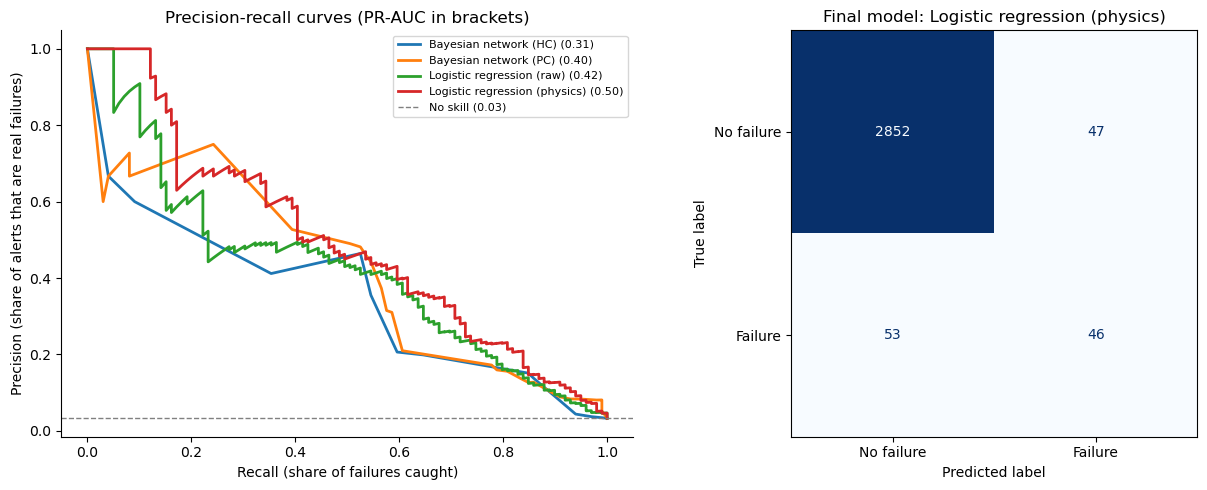

In [460]:
final = 'Logistic regression (physics)'
p_final = probs[final][1]
final_alerts = p_final >= best_threshold(y_train, probs[final][0])

fig, axes = plt.subplots(1, 2, figsize=(13, 5))
for name, (_, p_test) in probs.items():
    precision, recall, _ = precision_recall_curve(y, p_test)
    axes[0].plot(recall, precision, linewidth=2,
                 label=f'{name} ({average_precision_score(y, p_test):.2f})')
axes[0].axhline(y.mean(), color='gray', linestyle='--', linewidth=1,
                label=f'No skill ({y.mean():.2f})')
axes[0].set_xlabel('Recall (share of failures caught)')
axes[0].set_ylabel('Precision (share of alerts that are real failures)')
axes[0].set_title('Precision-recall curves (PR-AUC in brackets)')
axes[0].legend(fontsize=8, loc='upper right')
axes[0].spines[['top', 'right']].set_visible(False)

ConfusionMatrixDisplay(confusion_matrix(y, final_alerts),
                       display_labels=['No failure', 'Failure']).plot(
    ax=axes[1], cmap='Blues', colorbar=False)
axes[1].set_title(f'Final model: {final}')
plt.tight_layout()
plt.show()

**INTERPRETATION**

The precision-recall curves show the full trade-off for each model. The
physics-based model (red) sits at or near the top across most of the range.
All curves drop sharply after about 55% recall: beyond that point, each
extra failure caught costs many more false alarms.

The confusion matrix shows the final model at its balanced threshold: 46
failures caught, 53 missed, and 47 false alarms among 2,899 healthy machines
(1.6%).

**Catching more failures.** A missed failure (unplanned downtime) usually
costs more than a false alarm (an extra inspection). Lowering the final
model's threshold catches more failures at the cost of more false alarms.
Each threshold is set on the training data to catch the target share of
failures, then applied to the test data.

In [461]:
precision, recall, thresholds = precision_recall_curve(y_train,
                                                       probs[final][0])
healthy = (y == 0).sum()
rows = []
for target in [0.5, 0.8, 0.9]:
    threshold = thresholds[np.where(recall[:-1] >= target)[0][-1]]
    alerts = p_final >= threshold
    rows.append({'Target': f'{target:.0%} of failures',
                 'Failures caught': f'{alerts[y == 1].sum()} of {y.sum()}',
                 'False alarms': int(alerts[y == 0].sum()),
                 'Healthy machines flagged':
                     f'{alerts[y == 0].sum() / healthy:.1%}'})
print(pd.DataFrame(rows).set_index('Target').to_string())

                Failures caught  False alarms Healthy machines flagged
Target                                                                
50% of failures        47 of 99            52                     1.8%
80% of failures        84 of 99           430                    14.8%
90% of failures        92 of 99           751                    25.9%


**INTERPRETATION**

| To catch… | Failures caught | Healthy machines flagged |
|---|---|---|
| About half | 47 of 99 | 1.8% |
| About 80% | 84 of 99 | 14.8% (about 1 in 7) |
| About 90% | 92 of 99 | 25.9% (about 1 in 4) |

Catching the last failures gets expensive quickly. Which threshold to use is
a business decision that depends on the cost of a breakdown versus an
inspection.

### 4.5 Modeling summary

1. **Final model:** logistic regression with physics-based features
   (PR-AUC 0.50, ROC-AUC 0.93), significantly better than the raw-sensor
   version.
2. **Significant predictors (p < 0.001):** power (risk lowest near 6.6 kW),
   temperature difference (smaller gap = higher risk), strain (tool wear ×
   torque), and rotational speed (slower = riskier at a given power).
3. **Not significant:** product quality type, once operating conditions are
   known.
4. **Bayesian networks** identify the same drivers and give easy-to-read
   risk tables, but binning costs them some accuracy.
5. **Limitations:** the data is synthetic, and the physics-based features
   come from the same rules used to generate it, so real machines would be
   harder to predict. At a balanced threshold the model misses about half of
   all failures, and catching 80% means inspecting about 1 in 7 healthy
   machines.